PROGRAM STARTED - GAN IMAGE GENERATION

[1/5] Loading MNIST dataset...
Dataset ready: (5000, 28, 28, 1)

[2/5] Building Generator...
Generator created!

[3/5] Building Discriminator...
Discriminator created!

[4/5] Preparing training...

[5/5] GAN TRAINING STARTED!

Starting Epoch 1/3...
Generator Loss: 0.6328
Discriminator Loss: 1.1212
Generating sample images...


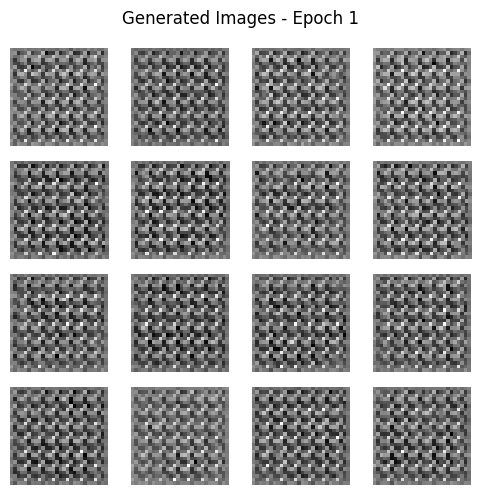


Starting Epoch 2/3...
Generator Loss: 0.7637
Discriminator Loss: 0.9379
Generating sample images...


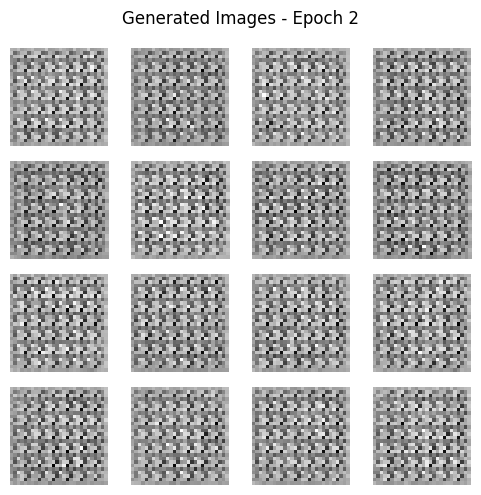


Starting Epoch 3/3...
Generator Loss: 0.7838
Discriminator Loss: 0.9832
Generating sample images...


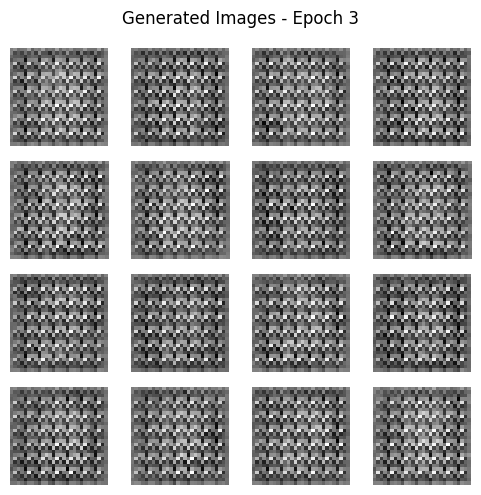


GAN TRAINING COMPLETED SUCCESSFULLY!


In [4]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

print("PROGRAM STARTED - GAN IMAGE GENERATION")

# 1. Load and preprocess data
print("\n[1/5] Loading MNIST dataset...")
(x_train, _), (_, _) = mnist.load_data()

x_train = x_train[:5000]
x_train = x_train[..., np.newaxis].astype("float32")
x_train = (x_train - 127.5) / 127.5

print("Dataset ready:", x_train.shape)

# 2. Build Generator
print("\n[2/5] Building Generator...")

latent_dim = 100
batch_size = 128

generator = models.Sequential([
    layers.Input(shape=(latent_dim,)),
    layers.Dense(7 * 7 * 128),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Reshape((7, 7, 128)),
    layers.Conv2DTranspose(
        64, 4, strides=2, padding="same"
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Conv2DTranspose(
        1, 4, strides=2, padding="same", activation="tanh"
    )
])

print("Generator created!")

# 3. Build Discriminator
print("\n[3/5] Building Discriminator...")

discriminator = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 4, strides=2, padding="same"),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dropout(0.3),
    layers.Conv2D(64, 4, strides=2, padding="same"),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(1, activation="sigmoid")
])

print("Discriminator created!")

# 4. Set up GAN training
print("\n[4/5] Preparing training...")

loss_fn = tf.keras.losses.BinaryCrossentropy()

gen_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002)
disc_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002)

@tf.function
def train_step(real_images):
    noise = tf.random.normal(
        [tf.shape(real_images)[0], latent_dim]
    )

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        gen_loss = loss_fn(
            tf.ones_like(fake_output), fake_output
        )

        real_loss = loss_fn(
            tf.ones_like(real_output), real_output
        )

        fake_loss = loss_fn(
            tf.zeros_like(fake_output), fake_output
        )

        disc_loss = real_loss + fake_loss

    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )
    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    gen_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )
    disc_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss


# Prepare dataset
dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(5000).batch(batch_size).prefetch(1)

# Fixed noise gives a consistent view of progress
seed = tf.random.normal([16, latent_dim])


def show_images(epoch):
    images = generator(seed, training=False)
    images = (images + 1) / 2

    plt.figure(figsize=(5, 5))

    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow(images[i, :, :, 0], cmap="gray")
        plt.axis("off")

    plt.suptitle(f"Generated Images - Epoch {epoch}")
    plt.tight_layout()
    plt.show()


# 5. Train GAN
print("\n[5/5] GAN TRAINING STARTED!")

EPOCHS = 3

for epoch in range(EPOCHS):
    gen_losses = []
    disc_losses = []

    print(f"\nStarting Epoch {epoch + 1}/{EPOCHS}...")

    for step, batch in enumerate(dataset):
        g_loss, d_loss = train_step(batch)

        gen_losses.append(float(g_loss))
        disc_losses.append(float(d_loss))

    print("Generator Loss:",
          round(np.mean(gen_losses), 4))
    print("Discriminator Loss:",
          round(np.mean(disc_losses), 4))

    print("Generating sample images...")
    show_images(epoch + 1)

print("\nGAN TRAINING COMPLETED SUCCESSFULLY!")
